In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import classification_report, confusion_matrix


In [3]:
# Cấu hình
DATA_DIR    = "/content/drive/MyDrive/Colab Notebooks/CV_CK_TOPIC12/rice_leaf_diseases"
IMG_SIZE    = (224, 224)    # Kích thước ảnh MobileNetV2 yêu cầu
BATCH_SIZE  = 16            # Số ảnh mỗi lô huấn luyện
NUM_CLASSES = 3             # 3 loại bệnh
SEED        = 42            # Hạt ngẫu nhiên để tái tạo kết quả

DISEASE_VI = {
    "Bacterial leaf blight": "Bệnh Bạc Lá",
    "Brown spot"           : "Bệnh Đốm Nâu",
    "Leaf smut"            : "Bệnh Đóm Than",
}

In [4]:
# ── Giai đoạn 1: Tiền xử lý và Tăng cường dữ liệu
#Data Augumentation
train_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input,   # Chuẩn hóa pixel về [-1, 1]
    rotation_range         = 30,                 # Xoay ảnh ngẫu nhiên ±30°
    width_shift_range      = 0.15,               # Dịch ngang tối đa 15%
    height_shift_range     = 0.15,               # Dịch dọc tối đa 15%
    shear_range            = 0.10,               # Biến dạng nghiêng nhẹ
    zoom_range             = 0.20,               # Phóng to/thu nhỏ ±20%
    horizontal_flip        = True,               # Lật gương ngang
    vertical_flip          = False,              # Không lật dọc (ảnh lá lúa mọc thẳng đứng)
    brightness_range       = [0.8, 1.2],         # Điều chỉnh độ sáng ±20%
    validation_split       = 0.20,               # 80% train | 20% val
)

val_datagen = ImageDataGenerator(
    preprocessing_function = preprocess_input,
    validation_split       = 0.20,
)

train_gen = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = "categorical",
    subset       = "training",
    seed         = SEED,
)

val_gen = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size  = IMG_SIZE,
    batch_size   = BATCH_SIZE,
    class_mode   = "categorical",
    subset       = "validation",
    seed         = SEED,
    shuffle      = False,   # Giữ thứ tự để so khớp nhãn khi đánh giá
)

class_names = list(train_gen.class_indices.keys())
print("Các lớp bệnh phát hiện:", class_names)

# Kiểm tra thứ tự class (quan trọng để nhãn khớp giữa train/val)
print("\nChỉ số lớp (train_gen):", train_gen.class_indices)
print("Chỉ số lớp (val_gen):  ", val_gen.class_indices)
assert train_gen.class_indices == val_gen.class_indices, \
    "⚠️  Thứ tự class của train_gen và val_gen không khớp!"
print("✅ Thứ tự class khớp nhau")


Found 96 images belonging to 3 classes.
Found 24 images belonging to 3 classes.
Các lớp bệnh phát hiện: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']

Chỉ số lớp (train_gen): {'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}
Chỉ số lớp (val_gen):   {'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}
✅ Thứ tự class khớp nhau


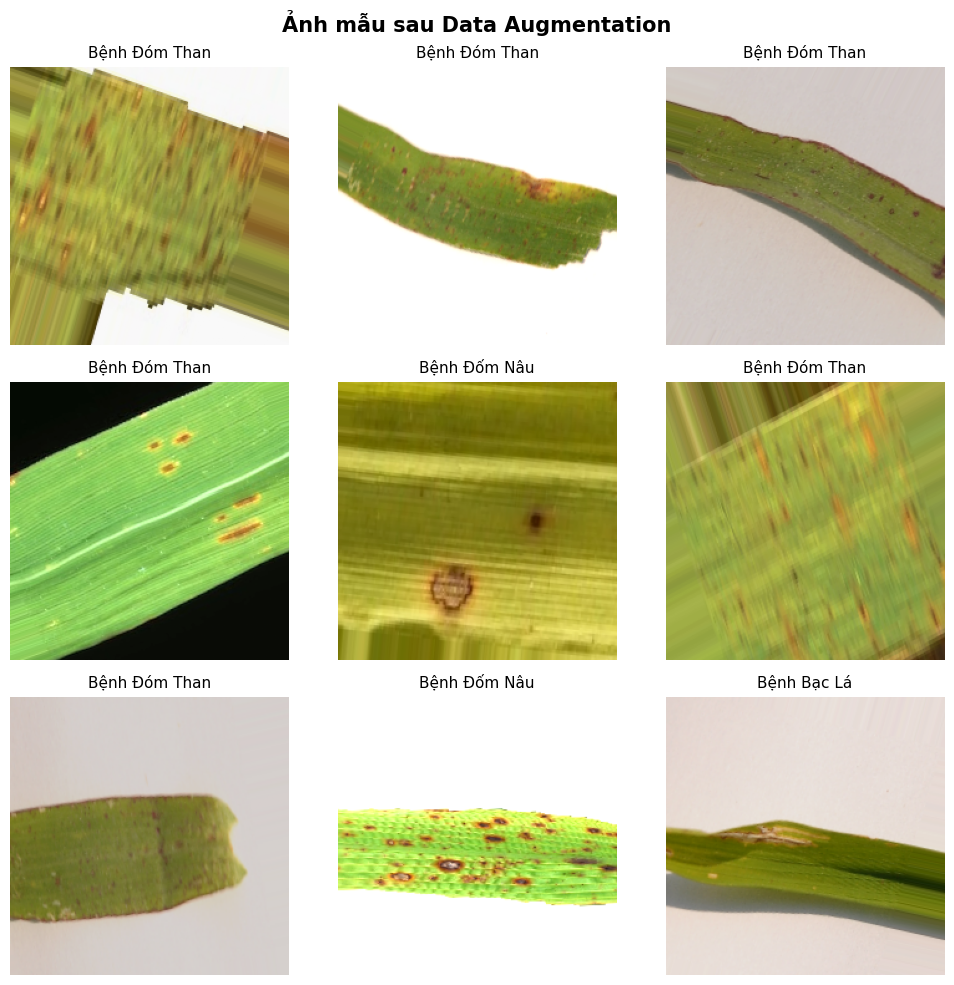

In [5]:
# Output minh họa - Giai đoạn 4: Hiển thị lưới ảnh mẫu sau Data Augmentation
import matplotlib.pyplot as plt

idx_to_class = {v: k for k, v in train_gen.class_indices.items()}

batch_imgs, batch_labels = next(train_gen)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
fig.suptitle("Ảnh mẫu sau Data Augmentation", fontsize=15, fontweight="bold")

for i, ax in enumerate(axes.flat):
    if i >= len(batch_imgs):
        ax.axis("off")
        continue
    # Ảnh đã qua preprocess_input (khoảng [-1, 1]) -> đưa về [0, 1] để hiển thị
    img_show = (batch_imgs[i] + 1.0) / 2.0
    img_show = np.clip(img_show, 0, 1)

    class_idx = int(np.argmax(batch_labels[i]))
    class_name_en = idx_to_class[class_idx]
    class_name_vi = DISEASE_VI.get(class_name_en, class_name_en)

    ax.imshow(img_show)
    ax.set_title(class_name_vi, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:
# ── Giai đoạn 2: Xây dựng mô hình (Backbone MobileNetV2...)
#Tải backbone MobileNetV2
backbone = MobileNetV2(
    input_shape  = IMG_SIZE + (3,),   # (224, 224, 3)
    include_top  = False,             # Bỏ lớp phân loại 1000 lớp gốc
    weights      = "imagenet",        # Trọng số đã học từ 1.2M ảnh ImageNet
)
backbone.trainable = False            # Đóng băng toàn bộ backbone

#Xây lớp phân loại riêng cho bài toán bệnh lúa
x      = backbone.output
x      = GlobalAveragePooling2D()(x)          # (7,7,1280) → vector 1280 chiều
x      = Dense(128, activation="relu")(x)    # Lớp ẩn học đặc trưng
x      = Dropout(0.4)(x)                     # Tắt 40% nơ-ron ngẫu nhiên → tránh overfitting
output = Dense(NUM_CLASSES, activation="softmax")(x)  # 3 xác suất tổng = 1.0

model  = Model(inputs=backbone.input, outputs=output)

model.compile(
    optimizer = Adam(learning_rate=1e-3),
    loss      = "categorical_crossentropy",
    metrics   = ["accuracy"],
)

print(f"\nTổng số tham số: {model.count_params():,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Tổng số tham số: 2,422,339


In [7]:
# Output minh họa - Giai đoạn 5: In chi tiết kiến trúc mô hình
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
# ── Giai đoạn 3: Huấn luyện mô hình (Training)
#Train
callbacks = [
    # Dừng sớm nếu val_loss không cải thiện sau 8 epoch
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    # Giảm learning rate khi val_loss bị plateau
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
]

# ── Giai đoạn 1: Huấn luyện lớp phân loại ──
print("\n" + "="*50)
print("  GIAI ĐOẠN 1: Huấn luyện lớp phân loại")
print("="*50)
history_1 = model.fit(
    train_gen,
    validation_data = val_gen,
    epochs          = 20,
    callbacks       = callbacks,
)

# ── Giai đoạn 2: Fine-tune 30 lớp cuối của backbone ──
print("\n" + "="*50)
print("  GIAI ĐOẠN 2: Fine-tuning backbone")
print("="*50)
backbone.trainable = True
fine_tune_from = len(backbone.layers) - 30   # Mở 30 lớp cuối

for layer in backbone.layers[:fine_tune_from]:
    layer.trainable = False   # Giữ đóng băng các lớp đầu

model.compile(
    optimizer = Adam(learning_rate=1e-5),   # LR nhỏ hơn 100 lần để tinh chỉnh
    loss      = "categorical_crossentropy",
    metrics   = ["accuracy"],
)

history_2 = model.fit(
    train_gen,
    validation_data = val_gen,
    epochs          = 15,
    callbacks       = callbacks,
)



  GIAI ĐOẠN 1: Huấn luyện lớp phân loại
Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 51s 7s/step - accuracy: 0.4688 - loss: 1.1641 - val_accuracy: 0.8750 - val_loss: 0.4113 - learning_rate: 0.0010
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.7604 - loss: 0.5197 - val_accuracy: 0.8750 - val_loss: 0.3244 - learning_rate: 0.0010
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step - accuracy: 0.7604 - loss: 0.4908 - val_accuracy: 0.7917 - val_loss: 0.3669 - learning_rate: 0.0010
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.8750 - loss: 0.3473 - val_accuracy: 0.8750 - val_loss: 0.2915 - learning_rate: 0.0010
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9062 - loss: 0.2099 - val_accuracy: 0.8750 - val_loss: 0.2433 - learning_rate: 0.0010
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.9271 - loss: 0.2040 - val_accuracy: 0.8333 - val_loss: 0.2775 - learning_rate: 0.0010
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.9479 - loss:

In [9]:
# Output minh họa - Giai đoạn 4: Bảng tóm tắt kết quả huấn luyện từng epoch
import pandas as pd

acc_all      = history_1.history["accuracy"]     + history_2.history["accuracy"]
val_acc_all  = history_1.history["val_accuracy"] + history_2.history["val_accuracy"]
loss_all     = history_1.history["loss"]         + history_2.history["loss"]
val_loss_all = history_1.history["val_loss"]     + history_2.history["val_loss"]

giai_doan = ["Giai đoạn 1"] * len(history_1.history["accuracy"]) + \
            ["Giai đoạn 2"] * len(history_2.history["accuracy"])

df_history = pd.DataFrame({
    "Epoch"        : list(range(1, len(acc_all) + 1)),
    "Giai đoạn"    : giai_doan,
    "Train Acc"    : [round(a, 4) for a in acc_all],
    "Val Acc"      : [round(a, 4) for a in val_acc_all],
    "Train Loss"   : [round(l, 4) for l in loss_all],
    "Val Loss"     : [round(l, 4) for l in val_loss_all],
})

print("\n=== BẢNG TÓM TẮT KẾT QUẢ HUẤN LUYỆN THEO EPOCH ===")
display(df_history)

best_epoch = df_history.loc[df_history["Val Acc"].idxmax()]
print(f"\nEpoch tốt nhất (Val Acc cao nhất): Epoch {int(best_epoch['Epoch'])} "
      f"({best_epoch['Giai đoạn']}) - Val Acc = {best_epoch['Val Acc']:.4f}")



=== BẢNG TÓM TẮT KẾT QUẢ HUẤN LUYỆN THEO EPOCH ===


,Epoch,Giai đoạn,Train Acc,Val Acc,Train Loss,Val Loss
0,1,Giai đoạn 1,0.4688,0.8750,1.1641,0.4113
1,2,Giai đoạn 1,0.7604,0.8750,0.5197,0.3244
2,3,Giai đoạn 1,0.7604,0.7917,0.4908,0.3669
3,4,Giai đoạn 1,0.8750,0.8750,0.3473,0.2915
4,5,Giai đoạn 1,0.9062,0.8750,0.2099,0.2433
5,6,Giai đoạn 1,0.9271,0.8333,0.2040,0.2775
6,7,Giai đoạn 1,0.9479,0.8750,0.1412,0.2808
7,8,Giai đoạn 1,0.9688,0.8333,0.0969,0.3035
8,9,Giai đoạn 1,0.9583,0.9167,0.1552,0.2251
9,10,Giai đoạn 1,0.9583,0.8750,0.1430,0.2227



Epoch tốt nhất (Val Acc cao nhất): Epoch 9 (Giai đoạn 1) - Val Acc = 0.9167


2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 733ms/step

=== BÁO CÁO PHÂN LOẠI ===
               precision    recall  f1-score   support

  Bệnh Bạc Lá       0.80      1.00      0.89         8
 Bệnh Đốm Nâu       1.00      1.00      1.00         8
Bệnh Đóm Than       1.00      0.75      0.86         8

     accuracy                           0.92        24
    macro avg       0.93      0.92      0.92        24
 weighted avg       0.93      0.92      0.92        24


Val Accuracy cuối: 0.9167


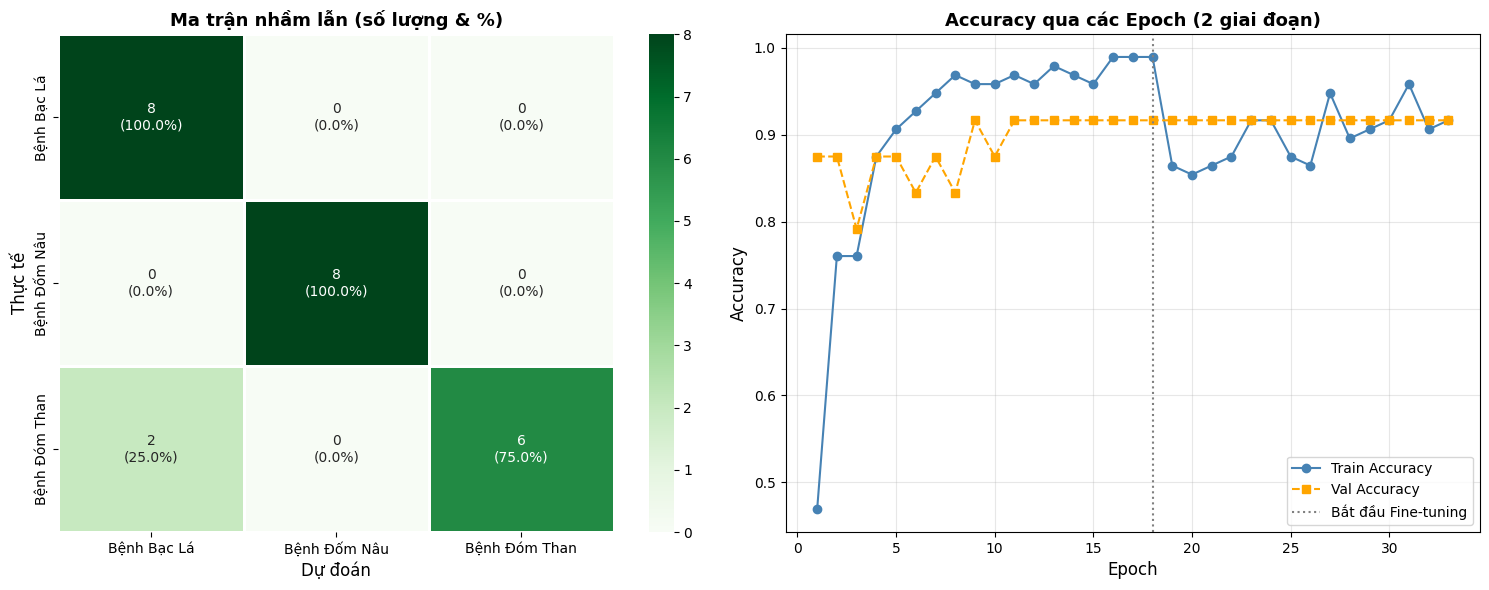

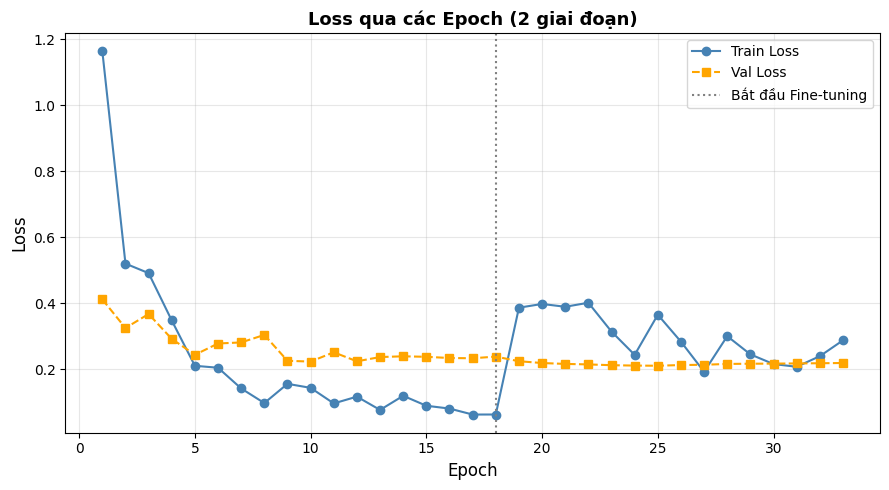

In [21]:
# ── Đánh giá mô hình trên tập Validation ──
from sklearn.metrics import confusion_matrix, classification_report

# Reset generator để đảm bảo đúng thứ tự
val_gen.reset()
y_pred_proba = model.predict(val_gen, verbose=1)
y_pred = np.argmax(y_pred_proba, axis=1)
y_true = val_gen.classes

cm = confusion_matrix(y_true, y_pred)

print("\n=== BÁO CÁO PHÂN LOẠI ===")
print(classification_report(
    y_true, y_pred,
    target_names=[DISEASE_VI.get(c, c) for c in class_names]
))

print(f"\nVal Accuracy cuối: {model.evaluate(val_gen, verbose=0)[1]:.4f}")


import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

ten_viet_labels = [DISEASE_VI.get(c, c) for c in class_names]

cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Confusion matrix (số lượng + phần trăm) ---
annot = np.array([f"{n}\n({p:.1f}%)" for n, p in zip(cm.flatten(), cm_norm.flatten())]).reshape(cm.shape)
sns.heatmap(cm, annot=annot, fmt="", cmap="Greens", cbar=True,
            xticklabels=ten_viet_labels, yticklabels=ten_viet_labels,
            linewidths=1, linecolor="white", ax=axes[0])
axes[0].set_xlabel("Dự đoán", fontsize=12)
axes[0].set_ylabel("Thực tế", fontsize=12)
axes[0].set_title("Ma trận nhầm lẫn (số lượng & %)", fontsize=13, fontweight="bold")

# --- Đường cong Accuracy/Loss gộp trong 1 subplot phụ ---
acc      = history_1.history["accuracy"]     + history_2.history["accuracy"]
val_acc  = history_1.history["val_accuracy"] + history_2.history["val_accuracy"]
epochs_range = range(1, len(acc) + 1)

axes[1].plot(epochs_range, acc, marker="o", label="Train Accuracy", color="steelblue")
axes[1].plot(epochs_range, val_acc, marker="s", label="Val Accuracy", color="orange", linestyle="--")
axes[1].axvline(x=len(history_1.history["accuracy"]), color="gray", linestyle=":",
                 label="Bắt đầu Fine-tuning")
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Accuracy", fontsize=12)
axes[1].set_title("Accuracy qua các Epoch (2 giai đoạn)", fontsize=13, fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("confusion_matrix_curves_chi_tiet.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Loss riêng, phóng to để dễ quan sát ---
loss      = history_1.history["loss"]     + history_2.history["loss"]
val_loss  = history_1.history["val_loss"] + history_2.history["val_loss"]

plt.figure(figsize=(9, 5))
plt.plot(epochs_range, loss, marker="o", label="Train Loss", color="steelblue")
plt.plot(epochs_range, val_loss, marker="s", label="Val Loss", color="orange", linestyle="--")
plt.axvline(x=len(history_1.history["loss"]), color="gray", linestyle=":", label="Bắt đầu Fine-tuning")
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Loss qua các Epoch (2 giai đoạn)", fontsize=13, fontweight="bold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [11]:
# Giai đoạn 4: Xây dựng hàm dự đoán (Inference)
def chuan_doan_la_lua(img_path, model, class_names, disease_vi=DISEASE_VI):
    # ── Bước 1: Đọc ảnh gốc để hiển thị ──────────────────────
    img_display = plt.imread(img_path)

    # ── Bước 2: Tiền xử lý ảnh đầu vào cho mô hình ───────────
    img     = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_arr = tf.keras.utils.img_to_array(img)   # Chuyển sang numpy array
    img_arr = preprocess_input(img_arr)           # Chuẩn hóa về [-1, 1]
    img_arr = np.expand_dims(img_arr, axis=0)     # Thêm chiều batch → (1, 224, 224, 3)

    # ── Bước 3: Dự đoán ──────────────────────────────────────
    xac_suat    = model.predict(img_arr, verbose=0)[0]   # Mảng 3 xác suất
    idx         = int(np.argmax(xac_suat))               # Vị trí xác suất cao nhất
    ten_benh_en = class_names[idx]                       # Tên bệnh tiếng Anh
    ten_benh_vi = disease_vi.get(ten_benh_en, ten_benh_en)  # Tên tiếng Việt
    do_tin_cay  = float(xac_suat[idx]) * 100             # Độ tin cậy (%)

    # ── Bước 4: Hiển thị kết quả ────────────────────────────
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(13, 5))

    # --- Ô trái: Ảnh lá lúa ---
    ax_img.imshow(img_display)
    ax_img.axis("off")
    ax_img.set_title("Ảnh lá lúa đưa vào", fontsize=12, pad=10)

    # Khung màu xanh lá bao quanh ảnh
    for spine in ax_img.spines.values():
        spine.set_edgecolor("green")
        spine.set_linewidth(3)

    # --- Ô phải: Biểu đồ thanh xác suất ---
    mau_sac = ["#e74c3c" if i == idx else "#bdc3c7" for i in range(len(class_names))]
    ten_viet_list = [disease_vi.get(c, c) for c in class_names]
    bars = ax_bar.barh(ten_viet_list, xac_suat * 100, color=mau_sac, edgecolor="white", height=0.5)

    ax_bar.set_xlabel("Xác suất (%)", fontsize=11)
    ax_bar.set_xlim(0, 110)
    ax_bar.set_title("Phân phối xác suất", fontsize=12)
    ax_bar.spines[["top", "right"]].set_visible(False)

    # Nhãn % trên mỗi thanh
    for bar, prob in zip(bars, xac_suat):
        ax_bar.text(
            bar.get_width() + 1.5,
            bar.get_y() + bar.get_height() / 2,
            f"{prob * 100:.1f}%",
            va="center", fontsize=11,
            fontweight="bold" if prob == xac_suat[idx] else "normal",
        )

    # --- Tiêu đề chính: tên bệnh + độ tin cậy ---
    fig.suptitle(
        f"CHẨN ĐOÁN: {ten_benh_vi}\n"
        f"Độ tin cậy: {do_tin_cay:.1f}%",
        fontsize=16, fontweight="bold", color="darkgreen", y=1.04,
    )

    plt.tight_layout()
    output_file = "ket_qua_chuan_doan.png"
    plt.savefig(output_file, dpi=150, bbox_inches="tight")
    plt.show()

    # In tóm tắt ra terminal
    print("\n" + "─" * 40)
    print(f"Bệnh phát hiện: {ten_benh_vi}")
    print(f"Tên khoa học: {ten_benh_en}")
    print(f" Độ tin cậy: {do_tin_cay:.2f}%")
    print("─" * 40)

    return ten_benh_vi, do_tin_cay

In [12]:
model.save("rice_leaf_disease_model.keras")
print("Đã lưu mô hình vào file: rice_leaf_disease_model.keras")

Đã lưu mô hình vào file: rice_leaf_disease_model.keras



Đang chẩn đoán: Bệnh Đóm Than (Leaf smut)


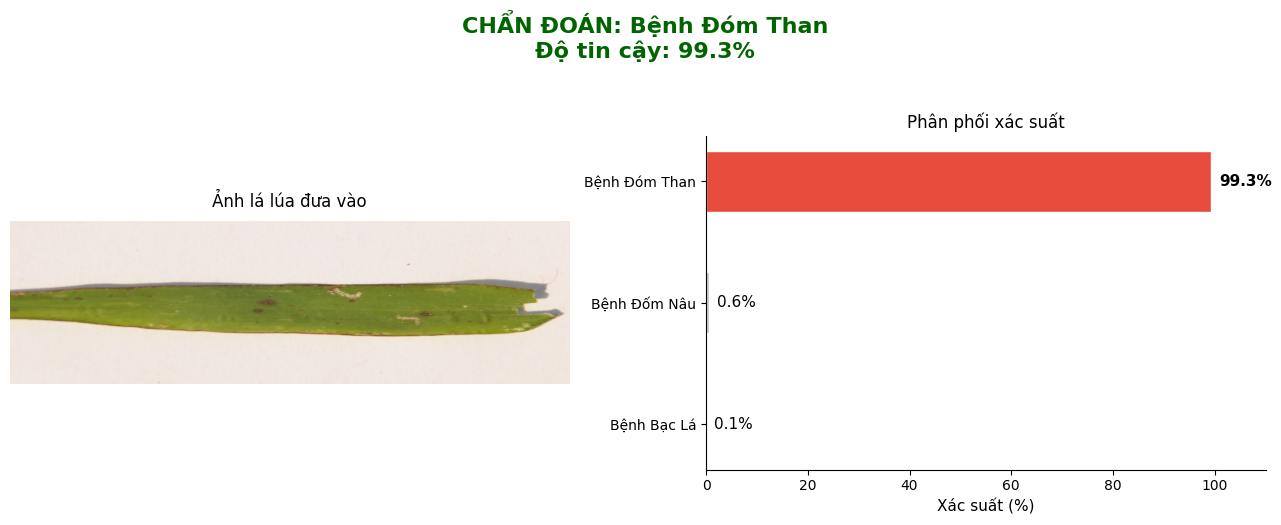


────────────────────────────────────────
Bệnh phát hiện: Bệnh Đóm Than
Tên khoa học: Leaf smut
 Độ tin cậy: 99.30%
────────────────────────────────────────


In [16]:
# ── Gọi hàm chẩn đoán cho ảnh thử nghiệm ──


anh_test = {
    "Leaf smut"            : "/content/drive/MyDrive/Colab Notebooks/CV_CK_TOPIC12/rice_leaf_diseases/Leaf smut/DSC_0293.JPG",
    # "Bacterial leaf blight": "<đường dẫn ảnh Bạc Lá>",
    # "Brown spot"           : "<đường dẫn ảnh Đốm Nâu>",
}

for ten_benh, duong_dan in anh_test.items():
    print(f"\n{'='*50}")
    print(f"Đang chẩn đoán: {DISEASE_VI.get(ten_benh, ten_benh)} ({ten_benh})")
    print('='*50)
    chuan_doan_la_lua(
        img_path    = duong_dan,
        model       = model,
        class_names = class_names,
    )


  GRAD-CAM — Trực quan hóa vùng mô hình chú ý

🌿 Đang phân tích: Bệnh Đóm Than (Leaf smut)


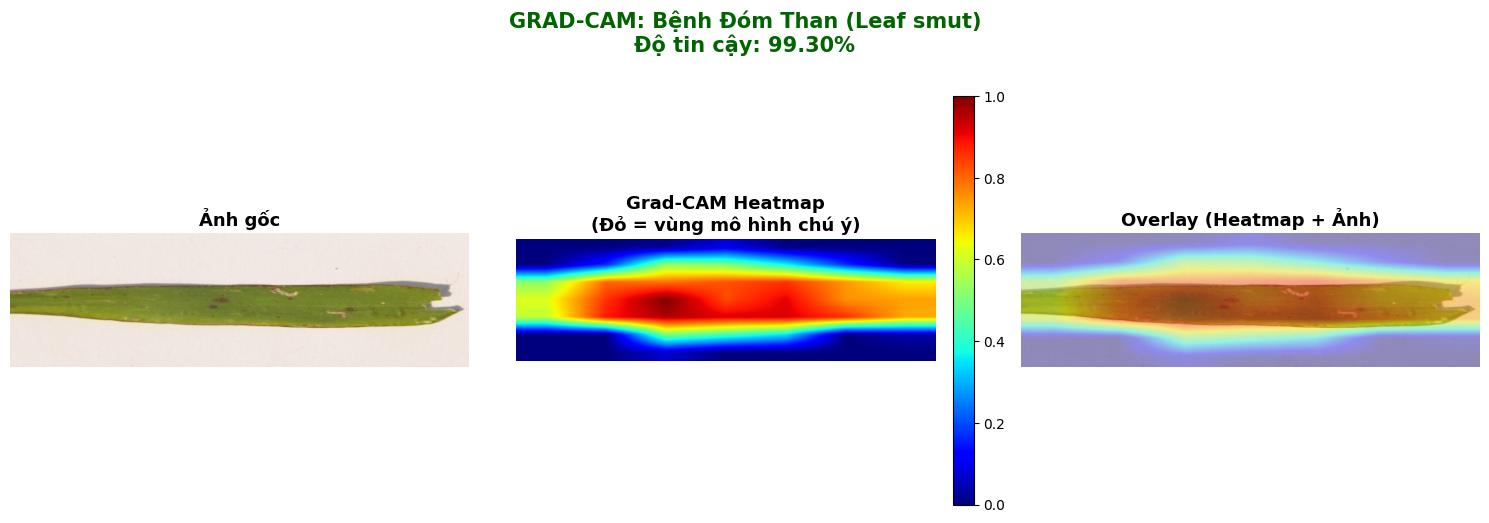


✅ Mô hình chú ý vào vùng ĐỎ/VÀNG trên lá → Dự đoán: Bệnh Đóm Than (99.30%)


In [18]:

#  Giai đoạn 5: Trực quan hóa Grad-CAM
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import cv2

# ── Hàm tạo Grad-CAM heatmap ──────────────────────────────────
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Tạo sub-model: input → last_conv_layer + output
    grad_model = tf.keras.models.Model(
        inputs  = model.inputs,
        outputs = [model.get_layer(last_conv_layer_name).output,
                   model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    # Gradient của class được chọn theo feature map của conv layer
    grads = tape.gradient(class_channel, conv_outputs)

    # Pooling gradient theo spatial dimensions
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Nhân feature map với gradient
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Chuẩn hóa về [0, 1]
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


# ── Hàm vẽ Grad-CAM overlay lên ảnh gốc ──────────────────────
def display_gradcam(img_path, model, class_names, disease_vi,
                    last_conv_layer_name="Conv_1", alpha=0.4):
    """
    Hiển thị ảnh gốc + Grad-CAM overlay + thông tin dự đoán.
    """
    # 1. Đọc ảnh gốc để hiển thị
    img_display = plt.imread(img_path)

    # 2. Tiền xử lý ảnh cho model
    img     = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_arr = tf.keras.utils.img_to_array(img)
    img_arr = preprocess_input(img_arr)
    img_arr_expanded = np.expand_dims(img_arr, axis=0)

    # 3. Dự đoán
    preds      = model.predict(img_arr_expanded, verbose=0)[0]
    pred_idx   = int(np.argmax(preds))
    pred_conf  = float(preds[pred_idx]) * 100
    pred_en    = class_names[pred_idx]
    pred_vi    = disease_vi.get(pred_en, pred_en)

    # 4. Tạo heatmap
    heatmap = make_gradcam_heatmap(img_arr_expanded, model,
                                   last_conv_layer_name, pred_idx)

    # 5. Resize heatmap về kích thước ảnh gốc
    h, w = img_display.shape[:2]
    heatmap_resized = cv2.resize(heatmap, (w, h))

    # 6. Chuyển heatmap sang màu (colormap JET)
    heatmap_color = cm.jet(heatmap_resized)[:, :, :3]  # bỏ alpha
    heatmap_color = (heatmap_color * 255).astype(np.uint8)

    # 7. Overlay lên ảnh gốc
    img_rgb = (img_display * 255).astype(np.uint8) if img_display.max() <= 1 else img_display.astype(np.uint8)
    overlay = (alpha * heatmap_color + (1 - alpha) * img_rgb).astype(np.uint8)

    # 8. Vẽ hình
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(img_display)
    axes[0].set_title("Ảnh gốc", fontsize=13, fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(heatmap_resized, cmap="jet")
    axes[1].set_title("Grad-CAM Heatmap\n(Đỏ = vùng mô hình chú ý)", fontsize=13, fontweight="bold")
    axes[1].axis("off")
    plt.colorbar(plt.cm.ScalarMappable(cmap="jet"), ax=axes[1],
                 fraction=0.046, pad=0.04)

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay (Heatmap + Ảnh)", fontsize=13, fontweight="bold")
    axes[2].axis("off")

    fig.suptitle(
        f"GRAD-CAM: {pred_vi} ({pred_en})\nĐộ tin cậy: {pred_conf:.2f}%",
        fontsize=15, fontweight="bold", color="darkgreen", y=1.02
    )
    plt.tight_layout()
    plt.savefig("gradcam_result.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n✅ Mô hình chú ý vào vùng ĐỎ/VÀNG trên lá → Dự đoán: {pred_vi} ({pred_conf:.2f}%)")


# ── Chạy Grad-CAM cho 1 ảnh từ mỗi class ─────────────────────
print("=" * 60)
print("  GRAD-CAM — Trực quan hóa vùng mô hình chú ý")
print("=" * 60)

# Danh sách ảnh mẫu từ mỗi class (thay đường dẫn nếu cần)
anh_mau = {
    "Leaf smut"            : "/content/drive/MyDrive/Colab Notebooks/CV_CK_TOPIC12/rice_leaf_diseases/Leaf smut/DSC_0293.JPG",
}

for ten_benh, duong_dan in anh_mau.items():
    print(f"\n🌿 Đang phân tích: {DISEASE_VI.get(ten_benh, ten_benh)} ({ten_benh})")
    display_gradcam(
        img_path           = duong_dan,
        model              = model,
        class_names        = class_names,
        disease_vi         = DISEASE_VI,
        last_conv_layer_name = "Conv_1",   # Lớp Conv cuối của MobileNetV2
        alpha              = 0.4           # Độ trong suốt overlay (0=chỉ ảnh, 1=chỉ heatmap)
    )